In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob

def cargar_imagen(nombre_base):
    archivos = glob.glob(f"{nombre_base}.*")
    if not archivos:
        raise FileNotFoundError(f"No se encontró el archivo '{nombre_base}'. Verifica que esté subido en Colab.")
    return cv2.imread(archivos[0], cv2.IMREAD_GRAYSCALE)

# Cargar en escala de grises e igualar dimensiones
img1 = cargar_imagen("PDI P6 pt1")
img2 = cargar_imagen("PDI P6 pt1.1")

alto, ancho = img1.shape
img2 = cv2.resize(img2, (ancho, alto))

**Parte 1** Ejercicio 1


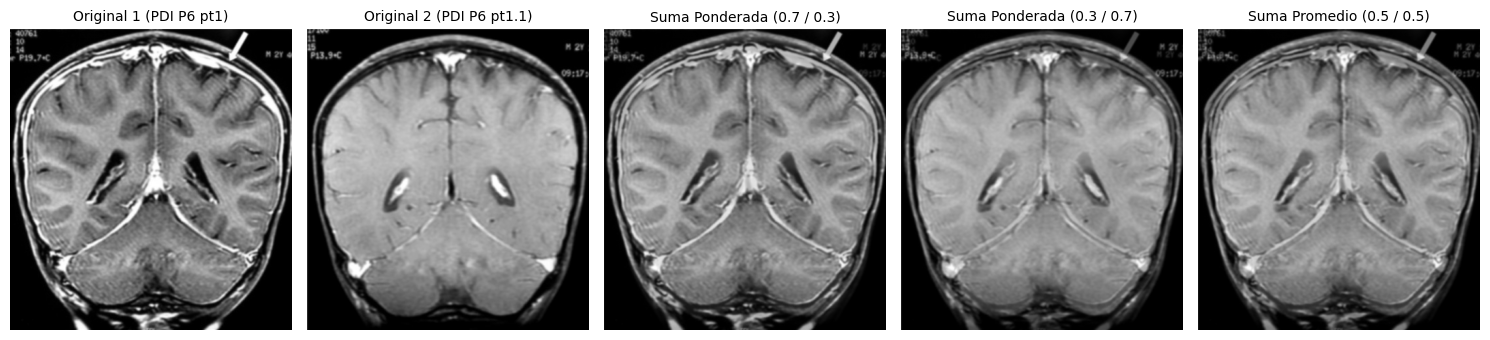

In [2]:
# Aplicar suma ponderada con diferentes pesos
suma_pond_1 = cv2.addWeighted(img1, 0.7, img2, 0.3, 0)
suma_pond_2 = cv2.addWeighted(img1, 0.3, img2, 0.7, 0)

# Aplicar suma promedio (50% y 50%)
suma_promedio = cv2.addWeighted(img1, 0.5, img2, 0.5, 0)

# Mostrar resultados junto con las originales
plt.figure(figsize=(15, 6))
titulos = [
    'Original 1 (PDI P6 pt1)',
    'Original 2 (PDI P6 pt1.1)',
    'Suma Ponderada (0.7 / 0.3)',
    'Suma Ponderada (0.3 / 0.7)',
    'Suma Promedio (0.5 / 0.5)'
]
imagenes = [img1, img2, suma_pond_1, suma_pond_2, suma_promedio]

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(imagenes[i], cmap='gray')
    plt.title(titulos[i], fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()

Ejercicio 2

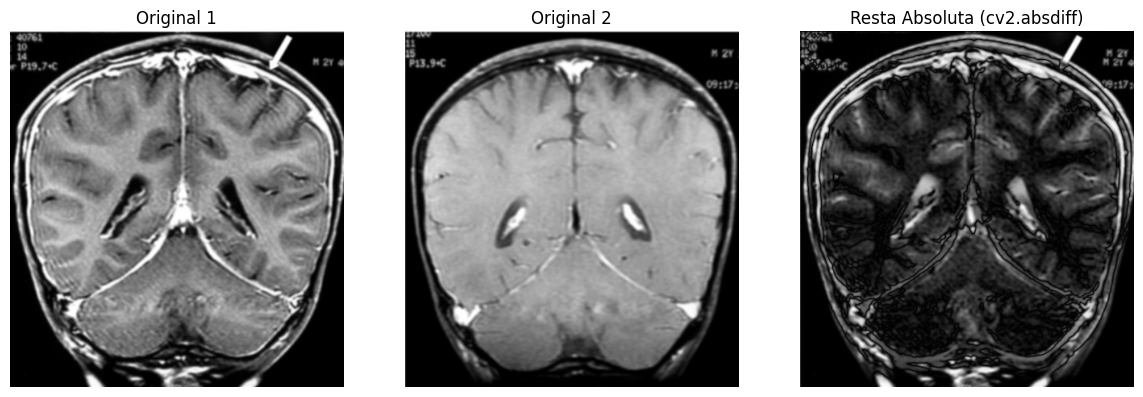

In [3]:
# Restar ambas imágenes usando cv2.absdiff para evitar valores negativos
resta_abs = cv2.absdiff(img1, img2)

# Mostrar resultados
plt.figure(figsize=(12, 4))
titulos = ['Original 1', 'Original 2', 'Resta Absoluta (cv2.absdiff)']
imagenes = [img1, img2, resta_abs]

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(imagenes[i], cmap='gray')
    plt.title(titulos[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

Ejercicio 3

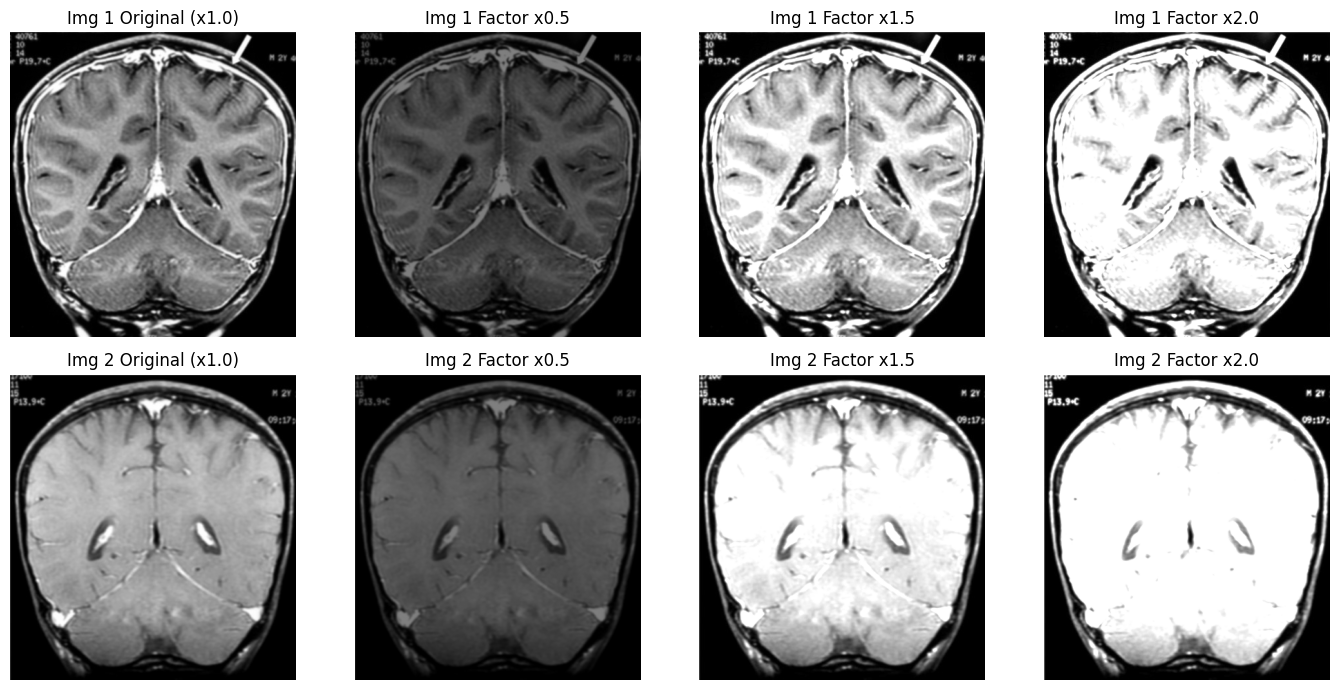

In [4]:
# Aplicar 3 diferentes factores de multiplicación a cada imagen
factores = [0.5, 1.5, 2.0]

plt.figure(figsize=(14, 7))

# Fila 1: Imagen 1
plt.subplot(2, 4, 1)
plt.imshow(img1, cmap='gray', vmin=0, vmax=255)
plt.title('Img 1 Original (x1.0)')
plt.axis('off')

for idx, f in enumerate(factores):
    img1_mult = cv2.multiply(img1, f)
    plt.subplot(2, 4, idx + 2)
    plt.imshow(img1_mult, cmap='gray', vmin=0, vmax=255)
    plt.title(f'Img 1 Factor x{f}')
    plt.axis('off')

# Fila 2: Imagen 2
plt.subplot(2, 4, 5)
plt.imshow(img2, cmap='gray', vmin=0, vmax=255)
plt.title('Img 2 Original (x1.0)')
plt.axis('off')

for idx, f in enumerate(factores):
    img2_mult = cv2.multiply(img2, f)
    plt.subplot(2, 4, idx + 6)
    plt.imshow(img2_mult, cmap='gray', vmin=0, vmax=255)
    plt.title(f'Img 2 Factor x{f}')
    plt.axis('off')

plt.tight_layout()
plt.show()

Ejercicio 4

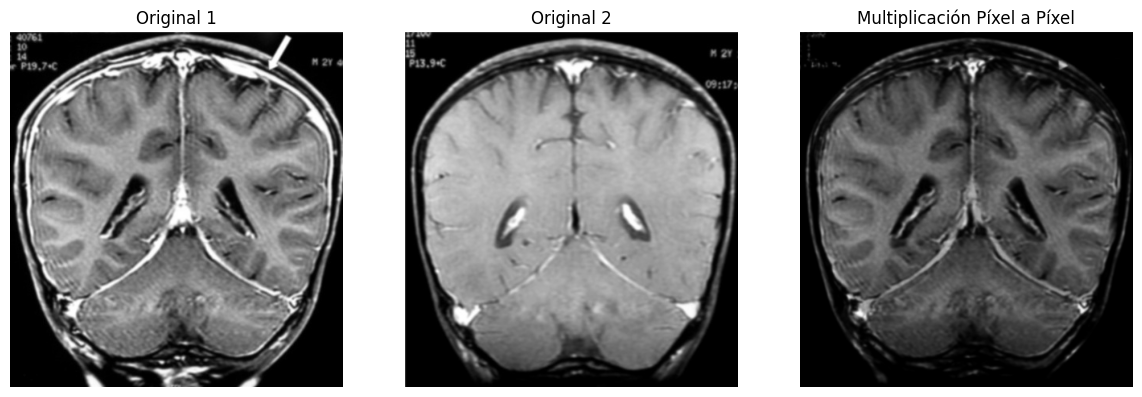

In [5]:
# Normalizar a [0, 1] antes de multiplicar píxel a píxel para evitar saturación total en blanco
img1_norm = img1.astype(np.float32) / 255.0
img2_norm = img2.astype(np.float32) / 255.0
mult_elemento = (img1_norm * img2_norm * 255).astype(np.uint8)

# Mostrar resultados
plt.figure(figsize=(12, 4))
titulos = ['Original 1', 'Original 2', 'Multiplicación Píxel a Píxel']
imagenes = [img1, img2, mult_elemento]

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(imagenes[i], cmap='gray')
    plt.title(titulos[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

**Parte 2** Ejercicio 1


In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob

# Buscar y cargar la imagen en escala de grises sin importar su extensión
archivos_pt2 = glob.glob("PDI P6 pt2.*")
if not archivos_pt2:
    raise FileNotFoundError("No se encontró el archivo 'PDI P6 pt2'. Verifica que esté subido en Colab.")

img_bajo_contraste = cv2.imread(archivos_pt2[0], cv2.IMREAD_GRAYSCALE)

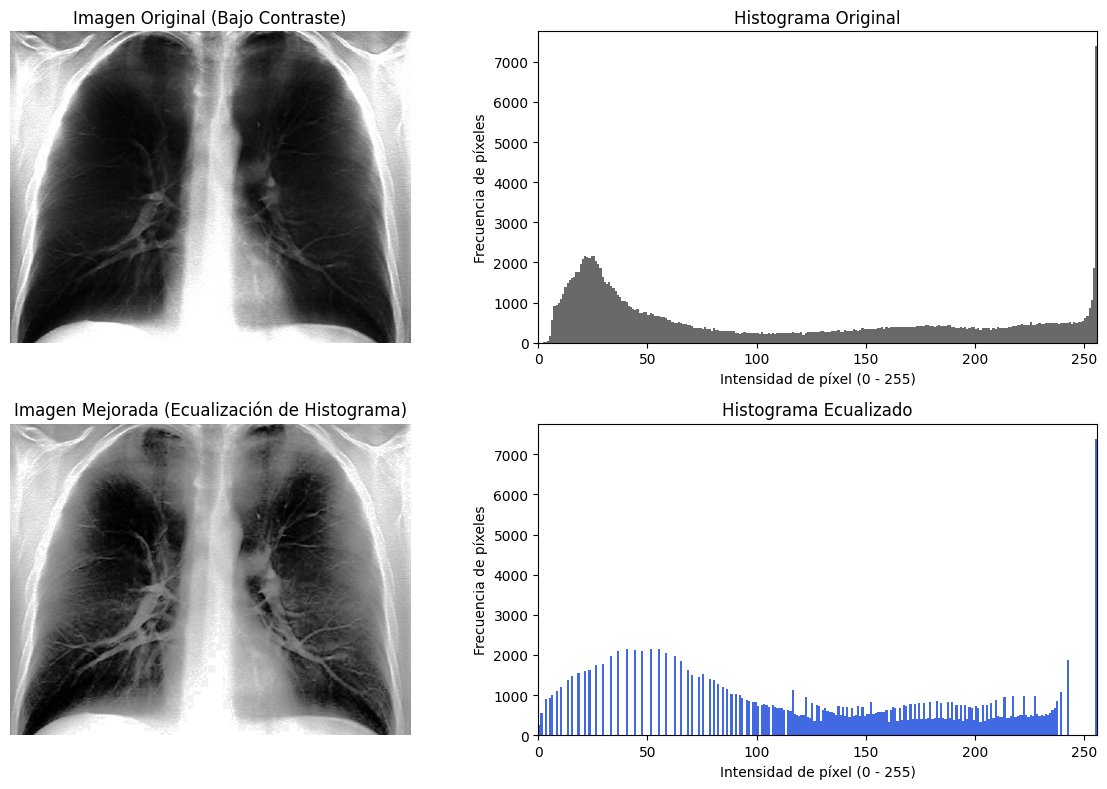

In [7]:
# Aplicar ecualización de histograma para mejorar el contraste
img_ecualizada = cv2.equalizeHist(img_bajo_contraste)

# Mostrar imagen original, imagen mejorada y comparar sus histogramas
plt.figure(figsize=(12, 8))

# 1. Imagen original
plt.subplot(2, 2, 1)
plt.imshow(img_bajo_contraste, cmap='gray', vmin=0, vmax=255)
plt.title('Imagen Original (Bajo Contraste)')
plt.axis('off')

# 2. Histograma original
plt.subplot(2, 2, 2)
plt.hist(img_bajo_contraste.ravel(), bins=256, range=[0, 256], color='dimgray')
plt.title('Histograma Original')
plt.xlabel('Intensidad de píxel (0 - 255)')
plt.ylabel('Frecuencia de píxeles')
plt.xlim([0, 256])

# 3. Imagen ecualizada
plt.subplot(2, 2, 3)
plt.imshow(img_ecualizada, cmap='gray', vmin=0, vmax=255)
plt.title('Imagen Mejorada (Ecualización de Histograma)')
plt.axis('off')

# 4. Histograma ecualizado
plt.subplot(2, 2, 4)
plt.hist(img_ecualizada.ravel(), bins=256, range=[0, 256], color='royalblue')
plt.title('Histograma Ecualizado')
plt.xlabel('Intensidad de píxel (0 - 255)')
plt.ylabel('Frecuencia de píxeles')
plt.xlim([0, 256])

plt.tight_layout()
plt.show()